# Yeast Protein Localisation Prediction

A protein's job depends on *where inside the cell* it ends up. From a yeast protein's amino-acid sequence, several scoring methods extract 8 numbers (signal-sequence and motif scores such as McGeoch's method, von Heijne's method, ALOM membrane scores…). Predict which of **10 localisation sites** (cytosol, nucleus, mitochondrion, membrane, secreted…) the protein belongs to. The catch is the class balance: cytosol and nucleus have hundreds of examples, while some sites have only a handful.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# UCI serves this dataset as a ready CSV at the dataset's data_url
df = pd.read_csv(io.BytesIO(download('https://archive.ics.uci.edu/static/public/110/data.csv')))
print(df.shape)
print('Samples per localisation site (note how uneven this is):')
print(df['localization_site'].value_counts())
df.head(3)

(1484, 10)
Samples per localisation site (note how uneven this is):
localization_site
CYT    463
NUC    429
MIT    244
ME3    163
ME2     51
ME1     44
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64


,Sequence_Name,mcg,gvh,alm,mit,erl,pox,vac,nuc,localization_site
0,ADT1_YEAST,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,ADT2_YEAST,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,ADT3_YEAST,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT


In [2]:
feats = ['mcg', 'gvh', 'alm', 'mit', 'erl', 'pox', 'vac', 'nuc']  # sequence-signal scores; Sequence_Name is just an ID
X = df[feats]; y = df['localization_site']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.6469
Logistic Regression accuracy: 0.5930
              precision    recall  f1-score   support

         CYT       0.59      0.69      0.64       116
         ERL       1.00      1.00      1.00         1
         EXC       0.71      0.56      0.62         9
         ME1       0.75      0.82      0.78        11
         ME2       0.46      0.46      0.46        13
         ME3       0.78      0.85      0.81        41
         MIT       0.67      0.57      0.62        61
         NUC       0.64      0.63      0.64       107
         POX       1.00      0.40      0.57         5
         VAC       0.00      0.00      0.00         7

    accuracy                           0.65       371
   macro avg       0.66      0.60      0.61       371
weighted avg       0.64      0.65      0.64       371



/home/hatch/workspace/ai-projects-portfolio/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hatch/workspace/ai-projects-portfolio/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hatch/workspace/ai-projects-portfolio/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

alm    0.225528
mit    0.187621
mcg    0.177077
gvh    0.166011
vac    0.115717
nuc    0.111324
pox    0.010533
erl    0.006190
dtype: float64


<Axes: title={'center': 'Which signals localise a protein?'}>

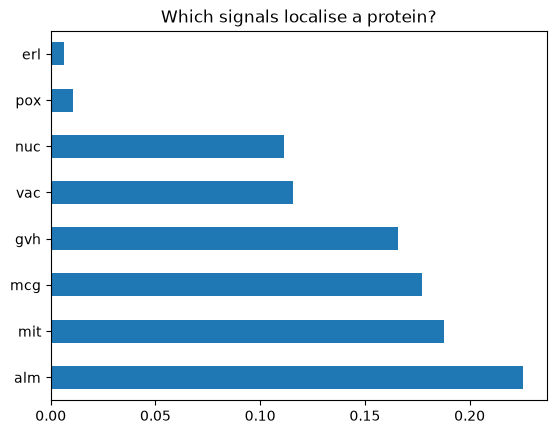

In [3]:
imp = pd.Series(rf.feature_importances_, index=feats).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which signals localise a protein?')